## **SETUP**

In [1]:
import pandas as pd
from scipy.stats import ttest_ind
import statsmodels.formula.api as smf
import numpy as np

In [2]:
b1_03 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/converted_csvs/Visit 1_Blocks 1&2_Identification of sample household_CLEAN.csv")
b15_03 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/converted_csvs/Visit 1_Block 15pt2 part 1_particulars of cash loans payable by the household to institutional or non-institutional agencies as on the date of survey and   transactions of loans_CLEAN.csv")
pmjdy_accounts = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/RS_Session_246_AU1483.csv")
state_population = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/Table_2A_State_Uts.csv")
b1_13 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2013/Visit 1_Block 1&2_Identification of sample household and particulars of field operations_CLEAN.csv")
b14_13 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2013/Visit 1_Block 14_particulars of cash loans payable by the household to institutional, non-institutional agencies as on the date of survey and transactions of loans  during 01.07.2012 to  date of survey_CLEAN.csv")
b3_13 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2013/Visit 1_Block 3_Household Characteristics_CLEAN.csv")
b1_19 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2019/Visit1  Level - 01 (Blocks 1 and 2) - Identification of sample household and  particulars of field operations_CLEAN.csv")
b12_19 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2019/Visit1  Level - 14 (Block 12) - particulars of cash loans payable by the household to institutional, non-institutional agencies as on the date of survey and transactions of loans_CLEAN.csv")
b4_19 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2019/Visit1  Level - 03 (Block 4) - Household characteristics_CLEAN.csv")

/var/folders/vk/w_cwhh610kl2dgwbqz3gqk000000gn/T/ipykernel_33752/4261632163.py:8: DtypeWarning: Columns (14,25,26,27,29) have mixed types. Specify dtype option on import or set low_memory=False.
  b1_19 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2019/Visit1  Level - 01 (Blocks 1 and 2) - Identification of sample household and  particulars of field operations_CLEAN.csv")
/var/folders/vk/w_cwhh610kl2dgwbqz3gqk000000gn/T/ipykernel_33752/4261632163.py:9: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  b12_19 = pd.read_csv("/Users/vaish/Desktop/TERMPAPER/2019/Visit1  Level - 14 (Block 12) - particulars of cash loans payable by the household to institutional, non-institutional agencies as on the date of survey and transactions of loans_CLEAN.csv")
/var/folders/vk/w_cwhh610kl2dgwbqz3gqk000000gn/T/ipykernel_33752/4261632163.py:10: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  b4_1

In [3]:
#PMJDY Intensity
state_population = state_population[["India/State/Union Territory", "Population 2011"]]
pmjdy_accounts = pmjdy_accounts[["State/UT Name", "Total Beneficiaries"]]

state_population = state_population.rename(
    columns={"India/State/Union Territory": "State"}
)

pmjdy_accounts = pmjdy_accounts.rename(
    columns={"State/UT Name": "State"}
)

state_population["State"] = state_population["State"].str.strip().str.title()
pmjdy_accounts["State"] = pmjdy_accounts["State"].str.strip().str.title()
pmjdy_intensity = pd.merge(
    state_population,
    pmjdy_accounts,
    on="State",
    how="inner"
)
pmjdy_intensity["intensity"] = pmjdy_intensity["Total Beneficiaries"]/pmjdy_intensity["Population 2011"] 
intensity_threshold = pmjdy_intensity["intensity"].median()
pmjdy_intensity["high_int_state"] = (pmjdy_intensity["intensity"] > intensity_threshold).astype(int)

state_order = [
    "Jammu & Kashmir",
    "Himachal Pradesh",
    "Punjab",
    "Chandigarh",
    "Uttarakhand",
    "Haryana",
    "Delhi",
    "Rajasthan",
    "Uttar Pradesh",
    "Bihar",
    "Sikkim",
    "Arunachal Pradesh",
    "Nagaland",
    "Manipur",
    "Mizoram",
    "Tripura",
    "Meghalaya",
    "Assam",
    "West Bengal",
    "Jharkhand",
    "Orissa",
    "Chhattisgarh",
    "Madhya Pradesh",
    "Gujarat",
    "Daman & Diu",
    "Dadra & Nagar Haveli",
    "Maharashtra",
    "Andhra Pradesh",
    "Karnataka",
    "Goa",
    "Lakshadweep",
    "Kerala",
    "Tamil Nadu",
    "Puducherry",
    "Andaman & Nicobar Islands",
    "Telangana"
]

state_id_map = {state: idx+1 for idx, state in enumerate(state_order)}
pmjdy_intensity["state_id"] = pmjdy_intensity["State"].map(state_id_map)
# pmjdy_intensity.head()

In [4]:
# 2003
# Step 1: HHID, District, State, Sector, Formal Loan Amount, Informal Loan Amount
# Step 2: Aggregate formal loan amount, informal loan amount at the district level
b1_03 = b1_03[["HHID", "State", "District", "Sector"]]
b15_03 = b15_03[["HHID", "B15_2_q3", "B15_2_q5", "B15_2_q6"]]
b15_03.rename(columns={
    "B15_2_q3": "year",
    "B15_2_q5": "amount_borrowed",
    "B15_2_q6": "credit_agency"
}, inplace=True)

b15_03 = b15_03[b15_03["year"] == 2002]
b15_03["formal_credit"] = (b15_03["credit_agency"] <= 8).astype(int)
df_03 = b15_03.merge(b1_03, on="HHID", how="inner")
df_03["State_District"] = (
    df_03["State"].astype(str).str.zfill(2) +
    df_03["District"].astype(str).str.zfill(2)
)

data_2003 = (
    df_03
    .groupby(["State_District", "formal_credit"])["amount_borrowed"]
    .sum()
    .unstack(fill_value=0)
    .rename(columns={1: "total_formal_credit", 0: "total_informal_credit"})
    .reset_index()
)
df_03["Rural"] = (df_03["Sector"] == 1).astype(int)
data_2003["state_code"] = data_2003["State_District"].str[:2].astype(int)
agg_additional = df_03.groupby("State_District").agg(
    avg_debt=("amount_borrowed", "mean"),
    majority_rural=("Rural", "mean")
).reset_index()
agg_additional["majority_rural"] = (agg_additional["majority_rural"] > 0.5).astype(int)
data_2003 = data_2003.merge(agg_additional, on="State_District", how="left")
state_lookup = pmjdy_intensity[["state_id", "high_int_state"]]
data_2003 = data_2003.merge(
    state_lookup,
    left_on="state_code",
    right_on="state_id",
    how="left"
)
data_2003.rename(columns={"high_int_state": "in_high_int_state"}, inplace=True)
data_2003 = data_2003.drop(columns=["state_code"])

In [5]:
data_2003.head()

,State_District,total_informal_credit,total_formal_credit,avg_debt,majority_rural,state_id,in_high_int_state
0,0101,75000.0,0.0,25000.000000,1,1.0,0.0
1,0102,1785000.0,890000.0,55729.166667,1,1.0,0.0
2,0103,62000.0,0.0,20666.666667,1,1.0,0.0
3,0104,50000.0,0.0,50000.000000,1,1.0,0.0
4,0105,364000.0,70000.0,21700.000000,1,1.0,0.0


In [6]:
# 2013
# Step 1: HHID, State_District, Sector, Formal Loan Amount, Informal Loan Amount, Intensity, 
# Step 2: Aggregate formal loan amount, informal loan amount, majority_rural, avg_debt at the district level
b1_13 = b1_13[["HHID", "State_District", "Sector"]]
b14_13 = b14_13[["HHID", "b14_q3", "b14_q5", "b14_q6"]]
b3_13 = b3_13[["HHID", "b3q1"]]
b14_13.rename(columns={
    "b14_q3": "year",
    "b14_q5": "amount_borrowed",
    "b14_q6": "credit_agency"
}, inplace=True)
b3_13.rename(columns={
    "b3q1": "hhsize"
}, inplace=True)
b14_13 = b14_13[b14_13["year"] == 2012]
b14_13["formal_credit"] = (b14_13["credit_agency"] <= 11).astype(int)
df_13 = b1_13.merge(b14_13, on="HHID", how="inner")
df_13 = df_13.merge(b3_13, on="HHID", how="inner")
df_13["State_District"] = df_13["State_District"].astype(str).str.zfill(4)
data_2013 = (
    df_13
    .groupby(["State_District", "formal_credit"])["amount_borrowed"]
    .sum()
    .unstack(fill_value=0)
    .rename(columns={1: "total_formal_credit", 0: "total_informal_credit"})
    .reset_index()
)
df_13["Rural"] = (df_13["Sector"] == 1).astype(int)
data_2013["State_District"] = data_2013["State_District"].astype(str).str.zfill(4)
agg_additional = df_13.groupby("State_District").agg(
    avg_debt=("amount_borrowed", "mean"),
    majority_rural=("Rural", "mean"),
    avg_hhsize=("hhsize", "mean")
).reset_index()
agg_additional["majority_rural"] = (agg_additional["majority_rural"] > 0.5).astype(int)
data_2013 = data_2013.merge(agg_additional, on="State_District", how="left")
data_2013["state_code"] = data_2013["State_District"].str[:2].astype(int)
state_lookup = pmjdy_intensity[["state_id", "high_int_state"]]
data_2013 = data_2013.merge(
    state_lookup,
    left_on="state_code",
    right_on="state_id",
    how="left"
)
data_2013.rename(columns={"high_int_state": "in_high_int_state"}, inplace=True)
data_2013 = data_2013.drop(columns=["state_code"])

data_2013.head()

,State_District,total_informal_credit,total_formal_credit,avg_debt,majority_rural,avg_hhsize,state_id,in_high_int_state
0,0101,1113000.0,1160000.0,54119.047619,1,5.904762,1.0,0.0
1,0102,566600.0,4669500.0,127709.756098,1,5.902439,1.0,0.0
2,0103,2489000.0,8555000.0,225387.755102,0,5.877551,1.0,0.0
3,0104,580000.0,2270000.0,75000.000000,1,5.842105,1.0,0.0
4,0105,1000000.0,2250000.0,92857.142857,1,5.942857,1.0,0.0


In [7]:
data_2013.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 632 entries, 0 to 631
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   State_District         632 non-null    object 
 1   total_informal_credit  632 non-null    float64
 2   total_formal_credit    632 non-null    float64
 3   avg_debt               632 non-null    float64
 4   majority_rural         632 non-null    int64  
 5   avg_hhsize             632 non-null    float64
 6   state_id               602 non-null    float64
 7   in_high_int_state      602 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 39.6+ KB


In [8]:
# 2019
# Step 1: HHID, State_District, Sector, Formal Loan Amount, Informal Loan Amount, Intensity, 
# Step 2: Aggregate formal loan amount, informal loan amount, majority_rural at the district level
b1_19 = b1_19[["HHID", "State_District", "Sector"]]
b12_19 = b12_19[["HHID", "b12q2", "b12q4", "b12q5"]]
b4_19 = b4_19[["HHID", "b4q1"]]
b12_19.rename(columns={
    "b12q2": "year",
    "b12q4": "amount_borrowed",
    "b12q5": "credit_agency"
}, inplace=True)
b4_19.rename(columns={
    "b4q1": "hhsize"
}, inplace=True)
b12_19 = b12_19[b12_19["year"] == 2018]
b12_19["formal_credit"] = (b12_19["credit_agency"] <= 13).astype(int)
df_19 = b1_19.merge(b12_19, on="HHID", how="inner")
df_19 = df_19.merge(b4_19, on="HHID", how="inner")
df_19["State_District"] = df_19["State_District"].astype(str).str.zfill(4)
data_2019 = (
    df_19
    .groupby(["State_District", "formal_credit"])["amount_borrowed"]
    .sum()
    .unstack(fill_value=0)
    .rename(columns={1: "total_formal_credit", 0: "total_informal_credit"})
    .reset_index()
)
df_19["Rural"] = (df_19["Sector"] == 1).astype(int)
data_2019["State_District"] = data_2019["State_District"].astype(str).str.zfill(4)
agg_additional = df_19.groupby("State_District").agg(
    avg_debt=("amount_borrowed", "mean"),
    majority_rural=("Rural", "mean"),
    avg_hhsize = ("hhsize", "mean"),
).reset_index()
agg_additional["majority_rural"] = (agg_additional["majority_rural"] > 0.5).astype(int)
data_2019 = data_2019.merge(agg_additional, on="State_District", how="left")
data_2019["state_code"] = data_2019["State_District"].str[:2].astype(int)
state_lookup = pmjdy_intensity[["state_id", "high_int_state"]]
data_2019 = data_2019.merge(
    state_lookup,
    left_on="state_code",
    right_on="state_id",
    how="left"
)
data_2019.rename(columns={"high_int_state": "in_high_int_state"}, inplace=True)
data_2019 = data_2019.drop(columns=["state_code"])

data_2019.head()

,State_District,total_informal_credit,total_formal_credit,avg_debt,majority_rural,avg_hhsize,state_id,in_high_int_state
0,0101,359000.0,920000.0,116272.727273,1,6.545455,1.0,0.0
1,0102,1733000.0,9485000.0,320514.285714,1,5.600000,1.0,0.0
2,0103,40000.0,1850000.0,118125.000000,1,4.625000,1.0,0.0
3,0104,415000.0,1410000.0,91250.000000,1,4.750000,1.0,0.0
4,0105,1938500.0,1160000.0,172138.888889,0,4.611111,1.0,0.0


In [9]:
data_2019.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 681 entries, 0 to 680
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   State_District         681 non-null    object 
 1   total_informal_credit  681 non-null    float64
 2   total_formal_credit    681 non-null    float64
 3   avg_debt               681 non-null    float64
 4   majority_rural         681 non-null    int64  
 5   avg_hhsize             681 non-null    float64
 6   state_id               651 non-null    float64
 7   in_high_int_state      651 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 42.7+ KB


## **SUMMARY STATS**

In [10]:
summary_2013 = {
    "Year": 2013,
    "Mean total borrowing": (data_2013["total_formal_credit"] + data_2013["total_informal_credit"]).mean(),
    "Mean formal borrowing": data_2013["total_formal_credit"].mean(),
    "Mean informal borrowing": data_2013["total_informal_credit"].mean(),
    "Number of districts": data_2013.shape[0]
}

summary_2019 = {
    "Year": 2019,
    "Mean total borrowing": (data_2019["total_formal_credit"] + data_2019["total_informal_credit"]).mean(),
    "Mean formal borrowing": data_2019["total_formal_credit"].mean(),
    "Mean informal borrowing": data_2019["total_informal_credit"].mean(),
    "Number of districts": data_2019.shape[0]
}

summary_table = pd.DataFrame([summary_2013, summary_2019])
summary_table["Pct_change_mean_formal"] = (
    summary_table["Mean formal borrowing"].pct_change() * 100
)
summary_table["Pct_change_mean_informal"] = (
    summary_table["Mean informal borrowing"].pct_change() * 100
)
summary_table

,Year,Mean total borrowing,Mean formal borrowing,Mean informal borrowing,Number of districts,Pct_change_mean_formal,Pct_change_mean_informal
0,2013,6.236992e+06,4.575152e+06,1.661840e+06,632,NaN,NaN
1,2019,9.601549e+06,7.514055e+06,2.087494e+06,681,64.236195,25.613435


In [11]:
data_2013["total_borrowing"] = data_2013["total_formal_credit"] + data_2013["total_informal_credit"]

baseline_table = data_2013.groupby("in_high_int_state").agg(
    avg_total_borrowing=("total_borrowing", "mean"),
    avg_formal_borrowing=("total_formal_credit", "mean"),
    avg_informal_borrowing=("total_informal_credit", "mean"),
    n_districts=("State_District", "count")
).reset_index()

baseline_table["State_Intensity"] = baseline_table["in_high_int_state"].map({1: "High-intensity", 0: "Low-intensity"})
baseline_table = baseline_table[[
    "State_Intensity", "avg_total_borrowing", "avg_formal_borrowing", "avg_informal_borrowing", "n_districts"
]]
baseline_table

,State_Intensity,avg_total_borrowing,avg_formal_borrowing,avg_informal_borrowing,n_districts
0,Low-intensity,8.892606e+06,6.658052e+06,2.234553e+06,251
1,High-intensity,4.719736e+06,3.378217e+06,1.341520e+06,351


In [12]:
mean_intensity = pmjdy_intensity["intensity"].mean()
median_intensity = pmjdy_intensity["intensity"].median()
std_intensity = pmjdy_intensity["intensity"].std()
prop_high_intensity = pmjdy_intensity["high_int_state"].mean()

intensity_summary = pd.DataFrame({
    "Mean intensity": [mean_intensity],
    "Median intensity": [median_intensity],
    "Standard deviation": [std_intensity],
    "Proportion high-intensity states": [prop_high_intensity]
})

intensity_summary

,Mean intensity,Median intensity,Standard deviation,Proportion high-intensity states
0,0.230311,0.221707,0.099257,0.5


In [13]:
data_2013["total_debt"] = data_2013["total_formal_credit"] + data_2013["total_informal_credit"]

high = data_2013[data_2013["in_high_int_state"] == 1]
low = data_2013[data_2013["in_high_int_state"] == 0]

rows = []

for var, name in [("total_formal_credit", "Formal debt 2013"),
                  ("total_informal_credit", "Informal debt 2013"),
                  ("total_debt", "Total debt 2013")]:
    mean_high = high[var].mean()
    mean_low = low[var].mean()
    t_stat, p_val = ttest_ind(high[var], low[var], equal_var=False)
    rows.append([name, mean_high, mean_low, p_val])

diff_in_means_table = pd.DataFrame(rows, columns=["Variable", "High intensity (mean)", "Low intensity (mean)", "p-value"])
diff_in_means_table

,Variable,High intensity (mean),Low intensity (mean),p-value
0,Formal debt 2013,3.378217e+06,6.658052e+06,1.000100e-07
1,Informal debt 2013,1.341520e+06,2.234553e+06,7.475542e-08
2,Total debt 2013,4.719736e+06,8.892606e+06,6.734873e-09


In [14]:
df_2013 = data_2013.copy() 

# 1. Simple Rural vs. Urban Gap (2013)
# majority_rural: 1 = Rural, 0 = Urban
rural_urban_stats = df_2013.groupby("majority_rural")[["total_formal_credit", "total_informal_credit"]].mean().reset_index()
rural_urban_stats["Sector"] = rural_urban_stats["majority_rural"].map({1: "Rural", 0: "Urban"})
print("=== TABLE 1: RURAL vs URBAN DEBT (2013) ===")
print(rural_urban_stats[["Sector", "total_formal_credit", "total_informal_credit"]])

# 2. The 4-Group Breakdown (Intensity x Sector)
# This shows the exact hierarchy of your groups
ddd_summary = df_2013.groupby(["in_high_int_state", "majority_rural"])[["total_formal_credit", "total_informal_credit"]].mean()

# Rename for readability
ddd_summary.index = ddd_summary.index.set_levels(["Low Intensity", "High Intensity"], level=0)
ddd_summary.index = ddd_summary.index.set_levels(["Urban", "Rural"], level=1)

print("\n=== TABLE 2: BASELINE MEANS BY GROUP (2013) ===")
print(ddd_summary)

=== TABLE 1: RURAL vs URBAN DEBT (2013) ===
  Sector  total_formal_credit  total_informal_credit
0  Urban         9.573069e+06           2.385507e+06
1  Rural         3.305839e+06           1.478052e+06

=== TABLE 2: BASELINE MEANS BY GROUP (2013) ===
                                  total_formal_credit  total_informal_credit
in_high_int_state majority_rural                                            
Low Intensity     Urban                  1.106818e+07           2.866803e+06
                  Rural                  4.814272e+06           1.970223e+06
High Intensity    Urban                  7.658499e+06           1.750723e+06
                  Rural                  2.616958e+06           1.268742e+06


## **ROBUSTNESS: PARALLEL PATHS**

In [15]:
formal_table = pd.DataFrame({
    "Year": [2003, 2013],
    "High-intensity mean formal": [
        data_2003[data_2003["in_high_int_state"] == 1]["total_formal_credit"].mean(),
        data_2013[data_2013["in_high_int_state"] == 1]["total_formal_credit"].mean()
    ],
    "Low-intensity mean formal": [
        data_2003[data_2003["in_high_int_state"] == 0]["total_formal_credit"].mean(),
        data_2013[data_2013["in_high_int_state"] == 0]["total_formal_credit"].mean()
    ]
})

formal_table["Difference (High - Low)"] = (
    formal_table["High-intensity mean formal"]
    - formal_table["Low-intensity mean formal"]
)

formal_table


,Year,High-intensity mean formal,Low-intensity mean formal,Difference (High - Low)
0,2003,8.130010e+05,1.849225e+06,-1.036224e+06
1,2013,3.378217e+06,6.658052e+06,-3.279836e+06


In [16]:
informal_table = pd.DataFrame({
    "Year": [2003, 2013],
    "High-intensity mean informal": [
        data_2003[data_2003["in_high_int_state"] == 1]["total_informal_credit"].mean(),
        data_2013[data_2013["in_high_int_state"] == 1]["total_informal_credit"].mean()
    ],
    "Low-intensity mean informal": [
        data_2003[data_2003["in_high_int_state"] == 0]["total_informal_credit"].mean(),
        data_2013[data_2013["in_high_int_state"] == 0]["total_informal_credit"].mean()
    ]
})

informal_table["Difference (High - Low)"] = (
    informal_table["High-intensity mean informal"]
    - informal_table["Low-intensity mean informal"]
)

informal_table

,Year,High-intensity mean informal,Low-intensity mean informal,Difference (High - Low)
0,2003,3.965068e+05,8.407174e+05,-444210.615584
1,2013,1.341520e+06,2.234553e+06,-893033.471527


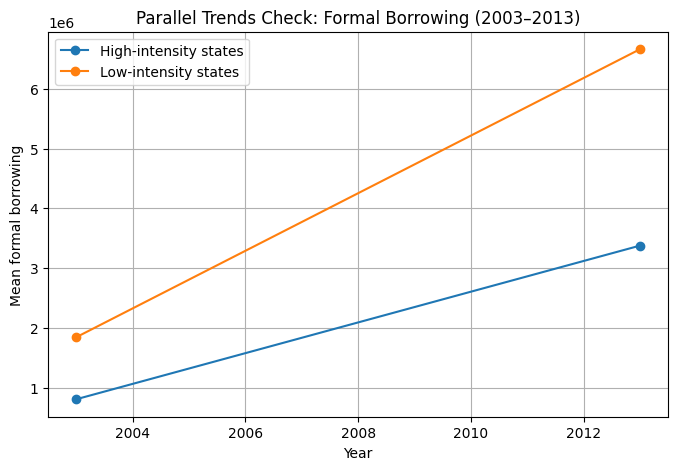

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(formal_table["Year"], formal_table["High-intensity mean formal"],
         marker='o', label="High-intensity states")
plt.plot(formal_table["Year"], formal_table["Low-intensity mean formal"],
         marker='o', label="Low-intensity states")

plt.xlabel("Year")
plt.ylabel("Mean formal borrowing")
plt.title("Parallel Trends Check: Formal Borrowing (2003–2013)")
plt.legend()
plt.grid(True)
plt.show()


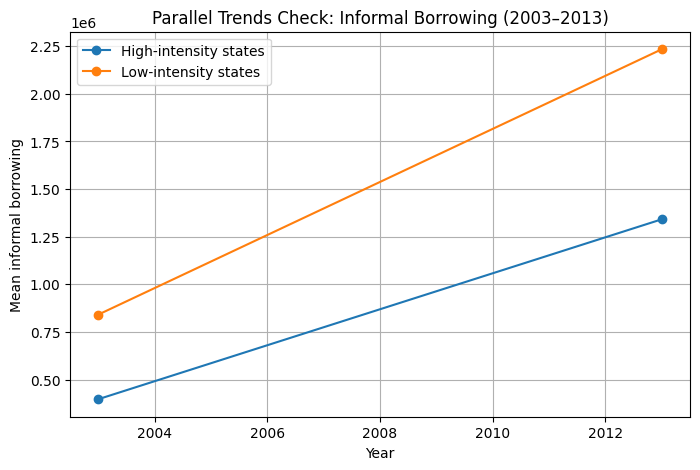

In [18]:
plt.figure(figsize=(8,5))

plt.plot(informal_table["Year"], informal_table["High-intensity mean informal"],
         marker='o', label="High-intensity states")
plt.plot(informal_table["Year"], informal_table["Low-intensity mean informal"],
         marker='o', label="Low-intensity states")

plt.xlabel("Year")
plt.ylabel("Mean informal borrowing")
plt.title("Parallel Trends Check: Informal Borrowing (2003–2013)")
plt.legend()
plt.grid(True)
plt.show()


In [19]:
import pandas as pd

# -----------------------------------------------
# 1. Create combined pre-period dataset
# -----------------------------------------------

data_2003["year"] = 2003
data_2013["year"] = 2013

pre = pd.concat([data_2003, data_2013], ignore_index=True)

# -----------------------------------------------
# 2. Function to compute rural–urban gap
# -----------------------------------------------

def rural_urban_gap(df, credit_var):
    rural_mean = df[df["majority_rural"] == 1][credit_var].mean()
    urban_mean = df[df["majority_rural"] == 0][credit_var].mean()
    return rural_mean - urban_mean

# -----------------------------------------------
# 3. Compute gaps by year × intensity group
# -----------------------------------------------

results = []

for year in [2003, 2013]:
    for group in [0, 1]:  # 0 = Low intensity, 1 = High intensity
        subset = pre[(pre["year"] == year) & (pre["in_high_int_state"] == group)]
        
        formal_gap = rural_urban_gap(subset, "total_formal_credit")
        informal_gap = rural_urban_gap(subset, "total_informal_credit")
        
        results.append({
            "Year": year,
            "HighIntensity": group,
            "Rural-Urban Formal Gap": formal_gap,
            "Rural-Urban Informal Gap": informal_gap
        })

gap_table = pd.DataFrame(results)
print("=== RURAL–URBAN GAPS (2003 vs 2013, HIGH vs LOW) ===")
print(gap_table)

# -----------------------------------------------
# 4. Compute ΔGap for High vs Low intensity states
# -----------------------------------------------

# Pivot to make it clearer
gap_wide = gap_table.pivot(index="HighIntensity", columns="Year")

# ΔGap (2013 - 2003)
delta_high = gap_wide.loc[1] - gap_wide.loc[1]
delta_low  = gap_wide.loc[0] - gap_wide.loc[0]

# Actually compute:
delta_high = gap_wide.loc[1].xs(2013, level=1) - gap_wide.loc[1].xs(2003, level=1)
delta_low  = gap_wide.loc[0].xs(2013, level=1) - gap_wide.loc[0].xs(2003, level=1)

ddd_check = pd.DataFrame({
    "ΔGap HighIntensity": delta_high,
    "ΔGap LowIntensity": delta_low,
    "Difference-in-Differences-in-Differences": delta_high - delta_low
})

print("\n=== DDD ASSUMPTION CHECK TABLE ===")
print(ddd_check)


=== RURAL–URBAN GAPS (2003 vs 2013, HIGH vs LOW) ===
   Year  HighIntensity  Rural-Urban Formal Gap  Rural-Urban Informal Gap
0  2003              0           -2.035860e+06            -310488.906780
1  2003              1           -1.662063e+06            -252209.964883
2  2013              0           -6.253904e+06            -896580.194304
3  2013              1           -5.041540e+06            -481981.237749

=== DDD ASSUMPTION CHECK TABLE ===
                          ΔGap HighIntensity  ΔGap LowIntensity  \
Rural-Urban Formal Gap         -3.379477e+06      -4.218044e+06   
Rural-Urban Informal Gap       -2.297713e+05      -5.860913e+05   

                          Difference-in-Differences-in-Differences  
Rural-Urban Formal Gap                               838567.369105  
Rural-Urban Informal Gap                             356320.014659  


In [20]:
import statsmodels.formula.api as smf
import pandas as pd

# ---------------------------------------------
# 1. Build pre-period panel (2003 + 2013)
# ---------------------------------------------
data_2003["year"] = 2003
data_2013["year"] = 2013

pre = pd.concat([data_2003, data_2013], ignore_index=True)

# Required variables:
# Rural (1/0), in_high_int_state (1/0), total_formal_credit, total_informal_credit

# ---------------------------------------------
# 2. Create Post indicator
# ---------------------------------------------
pre["Post"] = (pre["year"] == 2013).astype(int)

# ---------------------------------------------
# 3. Create THREE-WAY interaction (key DDD term)
# ---------------------------------------------
pre["DDD_term"] = pre["in_high_int_state"] * pre["majority_rural"] * pre["Post"]

# ---------------------------------------------
# 4. Fix clustering variable
# ---------------------------------------------
pre["cluster_id"] = pre["state_id"].astype("category").cat.codes

# ---------------------------------------------
# 5. Run DDD regression (FORMAL BORROWING)
# ---------------------------------------------
# Include all two-way interactions explicitly:
#   High*Rural, High*Post, Rural*Post
# Plus FE: C(State_District), C(year)

formal_model = smf.ols(
    """
    total_formal_credit ~ 
        DDD_term
        + in_high_int_state*majority_rural
        + in_high_int_state*Post
        +majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=pre
).fit()

# Align clusters with kept rows
formal_clusters = pre.loc[formal_model.model.data.row_labels, "cluster_id"]

did_ddd_formal = formal_model.get_robustcov_results(
    cov_type="cluster", 
    groups=formal_clusters
)

print("\n=== DDD PRE-TREND TEST (FORMAL BORROWING) ===")
print(did_ddd_formal.summary())


# ---------------------------------------------
# 6. Run DDD regression (INFORMAL BORROWING)
# ---------------------------------------------

informal_model = smf.ols(
    """
    total_informal_credit ~ 
        DDD_term
        + in_high_int_state*majority_rural
        + in_high_int_state*Post
        + majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=pre
).fit()

informal_clusters = pre.loc[informal_model.model.data.row_labels, "cluster_id"]

did_ddd_informal = informal_model.get_robustcov_results(
    cov_type="cluster",
    groups=informal_clusters
)

print("\n=== DDD PRE-TREND TEST (INFORMAL BORROWING) ===")
print(did_ddd_informal.summary())



=== DDD PRE-TREND TEST (FORMAL BORROWING) ===
                             OLS Regression Results                            
Dep. Variable:     total_formal_credit   R-squared:                       0.377
Model:                             OLS   Adj. R-squared:                  0.354
Method:                  Least Squares   F-statistic:                     258.8
Date:                 Thu, 27 Nov 2025   Prob (F-statistic):           6.93e-27
Time:                         09:54:27   Log-Likelihood:                -19170.
No. Observations:                 1148   AIC:                         3.842e+04
Df Residuals:                     1107   BIC:                         3.863e+04
Df Model:                           40                                         
Covariance Type:               cluster                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '


## **DDD**

In [21]:
# 1. Prepare Main Analysis Data (2013 vs 2019)
data_2013["year"] = 2013
data_2019["year"] = 2019

# Combine them
main_df = pd.concat([data_2013, data_2019], ignore_index=True)

# 2. Create Regression Variables
main_df["Post"] = (main_df["year"] == 2019).astype(int)
main_df["DDD_term"] = main_df["in_high_int_state"] * main_df["majority_rural"] * main_df["Post"]
main_df["cluster_id"] = main_df["state_id"].astype("category").cat.codes

# 3. Run Formal Credit Model
formal_model_main = smf.ols(
    """
    total_formal_credit ~ 
        DDD_term
        + in_high_int_state*majority_rural
        + in_high_int_state*Post
        + majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=main_df
).fit()

# Get robust results
formal_res = formal_model_main.get_robustcov_results(
    cov_type="cluster", 
    groups=main_df.loc[formal_model_main.model.data.row_labels, "cluster_id"]
)

# --- FIX: Find the index of 'DDD_term' to access the array correctly ---
ddd_idx_formal = formal_model_main.model.exog_names.index("DDD_term")

print("\n=== FINAL RESULTS 2013-2019 (FORMAL) ===")
# Use the index to get the value
print(f"DDD Coefficient: {formal_res.params[ddd_idx_formal]:.4f}")
print(f"P-value: {formal_res.pvalues[ddd_idx_formal]:.4f}")


# 4. Run Informal Credit Model
informal_model_main = smf.ols(
    """
    total_informal_credit ~ 
        DDD_term
        + in_high_int_state*majority_rural
        + in_high_int_state*Post
        + majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=main_df
).fit()

# Get robust results
informal_res = informal_model_main.get_robustcov_results(
    cov_type="cluster", 
    groups=main_df.loc[informal_model_main.model.data.row_labels, "cluster_id"]
)

# --- FIX: Find the index of 'DDD_term' again for the new model ---
ddd_idx_informal = informal_model_main.model.exog_names.index("DDD_term")

print("\n=== FINAL RESULTS 2013-2019 (INFORMAL) ===")
print(f"DDD Coefficient: {informal_res.params[ddd_idx_informal]:.4f}")
print(f"P-value: {informal_res.pvalues[ddd_idx_informal]:.4f}")
print(formal_res.summary())
print(informal_res.summary())


=== FINAL RESULTS 2013-2019 (FORMAL) ===
DDD Coefficient: 7660856.4649
P-value: 0.1212

=== FINAL RESULTS 2013-2019 (INFORMAL) ===
DDD Coefficient: -560289.5258
P-value: 0.3540
                             OLS Regression Results                            
Dep. Variable:     total_formal_credit   R-squared:                       0.336
Model:                             OLS   Adj. R-squared:                  0.314
Method:                  Least Squares   F-statistic:                     53.92
Date:                 Thu, 27 Nov 2025   Prob (F-statistic):           6.03e-16
Time:                         09:54:27   Log-Likelihood:                -21721.
No. Observations:                 1253   AIC:                         4.352e+04
Df Residuals:                     1212   BIC:                         4.373e+04
Df Model:                           40                                         
Covariance Type:               cluster                                         
                      

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '


## **ROBUSTNESS: PLACEBOS**

In [22]:
# Fake treatment group, random
placebo_df = main_df[main_df["in_high_int_state"] == 0].copy()

low_int_states = placebo_df["state_id"].unique()

np.random.seed(42)
fake_high_states = np.random.choice(low_int_states, size=len(low_int_states)//2, replace=False)

placebo_df["fake_high"] = placebo_df["state_id"].isin(fake_high_states).astype(int)
placebo_df["Post"] = (placebo_df["year"] == 2019).astype(int)

placebo_df["Placebo_DDD"] = placebo_df["fake_high"] * placebo_df["majority_rural"] * placebo_df["Post"]
placebo_df["cluster_id"] = placebo_df["state_id"].astype("category").cat.codes

model_fake_treatment = smf.ols(
    """
    total_formal_credit ~ 
        Placebo_DDD
        + fake_high*majority_rural
        + fake_high*Post
        + majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=placebo_df
).fit()

res_fake_treatment = model_fake_treatment.get_robustcov_results(
    cov_type="cluster", 
    groups=placebo_df.loc[model_fake_treatment.model.data.row_labels, "cluster_id"]
)

print("=== ROBUSTNESS CHECK 1: FAKE TREATMENT GROUP ===")
print(res_fake_treatment.summary())

=== ROBUSTNESS CHECK 1: FAKE TREATMENT GROUP ===
                             OLS Regression Results                            
Dep. Variable:     total_formal_credit   R-squared:                       0.356
Model:                             OLS   Adj. R-squared:                  0.325
Method:                  Least Squares   F-statistic:                     174.5
Date:                 Thu, 27 Nov 2025   Prob (F-statistic):           2.61e-14
Time:                         09:54:27   Log-Likelihood:                -9028.0
No. Observations:                  512   AIC:                         1.810e+04
Df Residuals:                      488   BIC:                         1.821e+04
Df Model:                           23                                         
Covariance Type:               cluster                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 25, but rank is 6
  warnings.warn('covariance of constraints does not have full '


In [23]:
# Fake outcome - avg_hhsize
placebo_model_hh = smf.ols(
    """
    avg_hhsize ~ 
        DDD_term
        + in_high_int_state*majority_rural
        + in_high_int_state*Post
        + majority_rural*Post
        + C(state_id)
        + C(year)
    """,
    data=main_df
).fit()

# --- Step 3: Get Robust Standard Errors (Clustered) ---
placebo_res_hh = placebo_model_hh.get_robustcov_results(
    cov_type="cluster", 
    groups=main_df.loc[placebo_model_hh.model.data.row_labels, "cluster_id"]
)

# --- Step 4: Extract and Print Results Safely ---

# Find the numeric index of the DDD term to access the results array
ddd_idx = placebo_model_hh.model.exog_names.index("DDD_term")

coeff = placebo_res_hh.params[ddd_idx]
pval = placebo_res_hh.pvalues[ddd_idx]

print("\n=== ROBUSTNESS CHECK RESULTS: FAKE OUTCOME (HH SIZE) ===")
print(f"Placebo Coefficient: {coeff:.4f}")
print(f"P-value: {pval:.4f}")

print(placebo_res_hh.summary())


=== ROBUSTNESS CHECK RESULTS: FAKE OUTCOME (HH SIZE) ===
Placebo Coefficient: -0.0955
P-value: 0.6155
                            OLS Regression Results                            
Dep. Variable:             avg_hhsize   R-squared:                       0.510
Model:                            OLS   Adj. R-squared:                  0.494
Method:                 Least Squares   F-statistic:                     22.23
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           1.91e-10
Time:                        09:54:27   Log-Likelihood:                -1054.9
No. Observations:                1253   AIC:                             2192.
Df Residuals:                    1212   BIC:                             2402.
Df Model:                          40                                         
Covariance Type:              cluster                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
------

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '
